# 美国国债收益率曲线的因子载荷是否随时间变化：研究 notebook（第 9 周基准 → 序列相关稳健检验）

这本 notebook 是项目的主工作记录：每一步的问题、做法、图、表和结论都在这里，按时间顺序排列。

- **读取的结果**：`results/final_tables.md`（第 9 周冻结表）和 `results/serial/*.csv`（第 10 周以后的模拟与实证汇总）。图由 `python code/run.py figures` 从这些文件重画，本 notebook 直接显示。
- **现场运行的部分**：第 9 节的新检验示例、第 11 节的代码对照抽查、第 12 节 Treasury 实证（B 较小，几分钟内跑完）。完整的 Monte Carlo 不在 notebook 里重跑，命令见 README。
- **数据边界**：JKV（CRSP / Fama–Bliss）原始面板不公开，相关实证数字是冻结结果；Treasury 实证用仓库里的 H.15 文件重跑。

**一句话结论（当前）**：原 Su–Wang 检验在独立误差下表现很好，但收益率残差有强持续性，原 bootstrap 因此几乎总是误报。新的 sieve-AR GLS-J 检验保留 Su–Wang 的原假设和“局部载荷 vs 全样本载荷”的比较，在 16 种 null 设定 × 2 个数据集共 32 格中的 27 格 size 落在 0.8–7.6%，power 高于 AR bootstrap。剩下的弱点是各期限噪音波动按不同比例变化时 size 为 8–15%。初步实证：三因子固定载荷在 1990–2009 被拒绝，四因子不被拒绝。

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name in ("notebook", "code") else ROOT
sys.path.insert(0, str(ROOT / "code"))
import serial_robust as sr
S = ROOT / "results" / "serial"
FIG = ROOT / "figures"
pd.set_option("display.width", 200, "display.max_columns", 30)
def fig(name, width=900): display(Image(filename=str(FIG / name), width=width))
def csv(name): return pd.read_csv(S / name)
print("repo root:", ROOT.name)

repo root: treasury-yield-curve-factor-stability


## 1. 研究问题、模型和数据

模型：$X_{it}=\lambda_i(t)'F_t+e_{it}$，原假设 $H_0:\lambda_i(t)=\lambda_i$（载荷固定）。Su–Wang（2017）比较核加权的局部 PCA 拟合和全样本 PCA 拟合，差距大就拒绝。

| 面板 | 内容 | 用途 |
|---|---|---|
| JKV17 | CRSP 非平滑 Fama–Bliss 零息收益率，17 个期限，1970–2009 月度 | 主历史样本（不公开再分发，仅提供校准参数） |
| Treasury8 / CMT | 官方 par 曲线 8 个期限（3 个月–10 年），H.15 月度 | 公开数据；1990–2009 与财政部月末 par 曲线逐项一致 |

研究问题分两层：(Q1) 固定的 3 或 4 个因子够不够；(Q2) 给定因子数，载荷是否随时间变化。

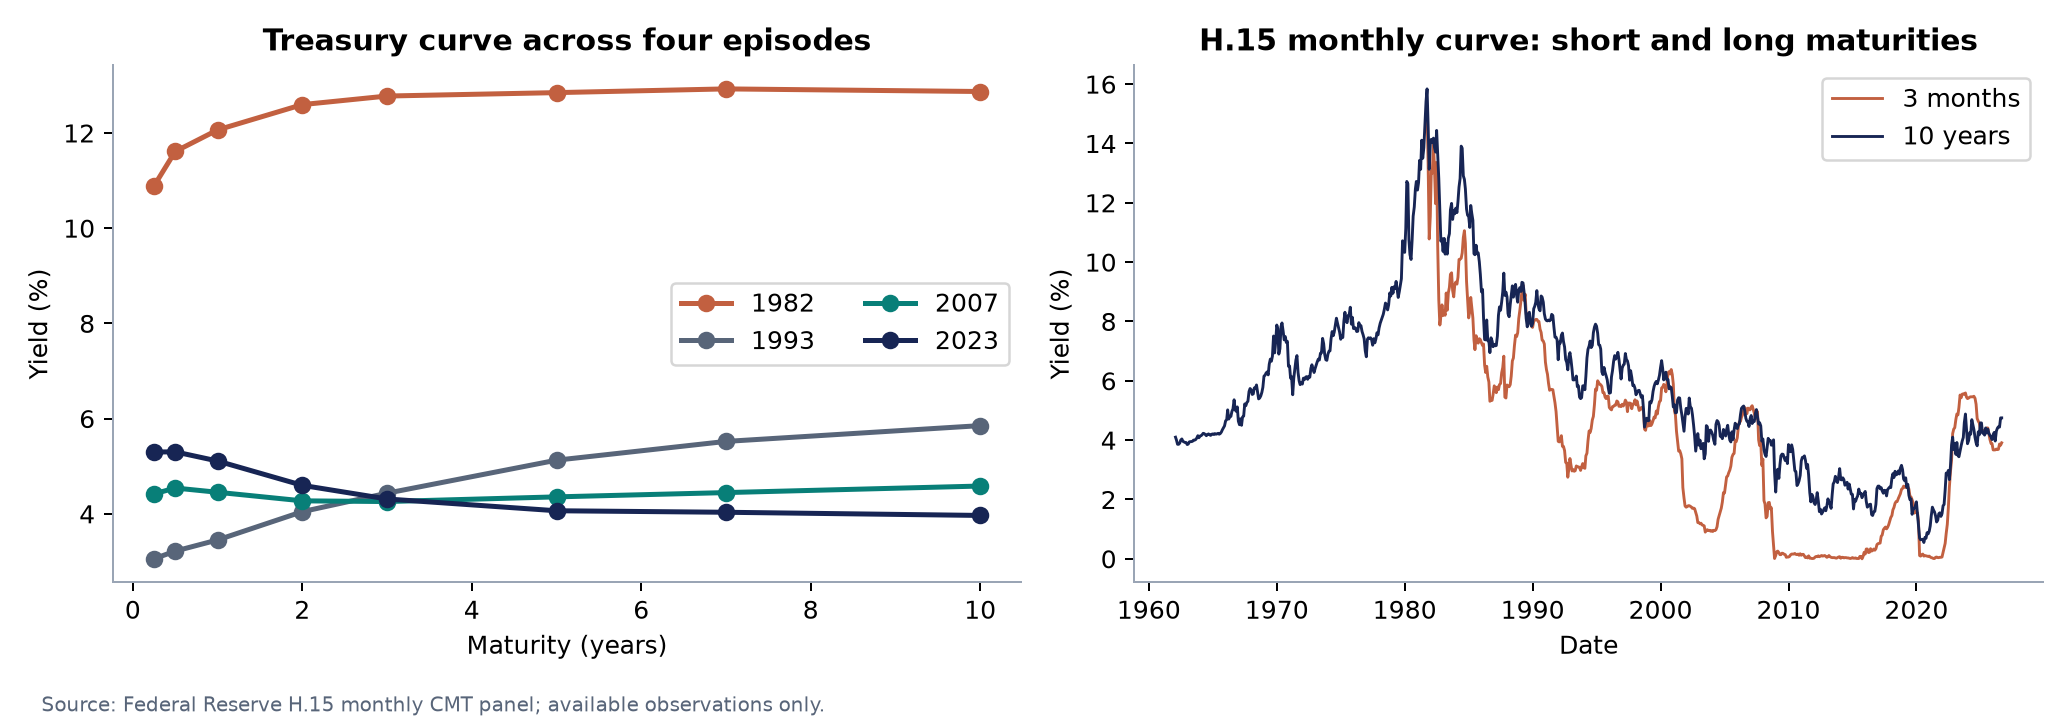

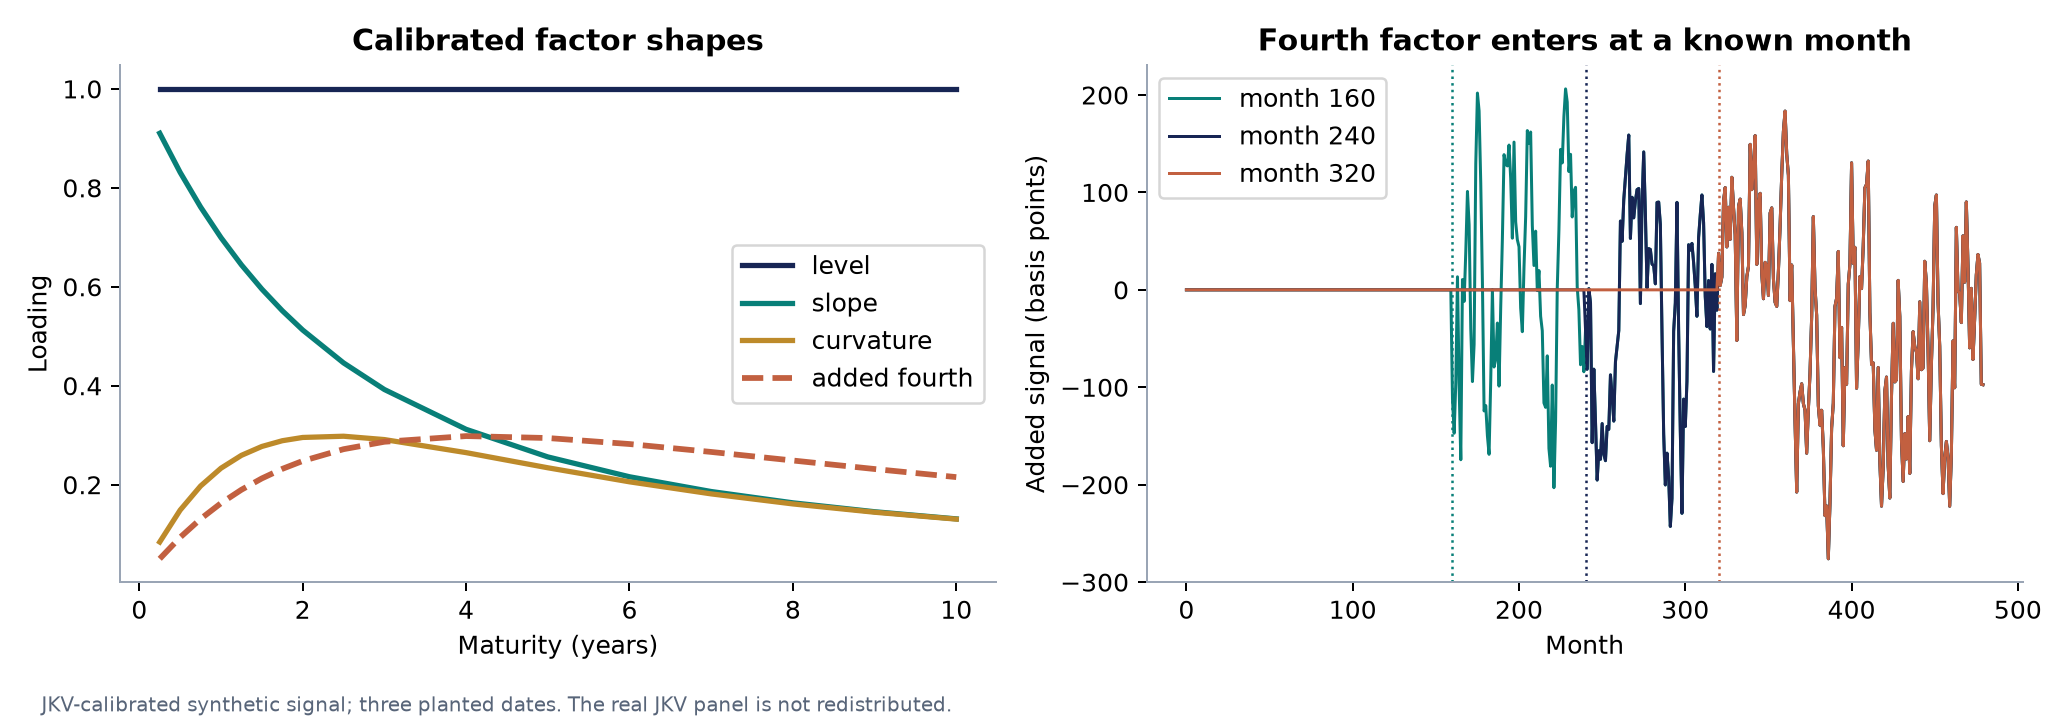

In [2]:
fig("01_treasury_yields.png"); fig("02_simulation_design.png")

## 2. 第 9 周基准：独立误差下，原检验的 size 和 power 都好

模拟：JKV 校准，T = 480，三因子 null；备择是第四因子在第 160/240/320 月出现。final 种子只用一次，500 个面板。

## 表 G　定稿：final 种子（从未用于选方法），500 个面板

| 方法 | size % | s.e. | power s=1 τ=160 | power s=1 τ=240 | power s=1 τ=320 | power s=0.5 τ=160 | power s=0.5 τ=240 | power s=0.5 τ=320 | ±24 s=1 τ=160 | ±24 s=1 τ=240 | ±24 s=1 τ=320 | ±24 s=0.5 τ=160 | ±24 s=0.5 τ=240 | ±24 s=0.5 τ=320 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Gated-split @5% | 3.8 | 0.9 | 93.8 | 93.2 | 90.2 | 83.4 | 82.0 | 69.6 | 57 | 80 | 87 | 21 | 39 | 48 |
| Gated-split @1% | 1.2 | 0.5 | 93.8 | 93.2 | 90.2 | 69.8 | 72.6 | 58.0 | 57 | 80 | 87 | 19 | 35 | 40 |
| Full-sample test @1% | 1.2 | 0.5 | 100.0 | 100.0 | 99.8 | 76.6 | 80.2 | 68.4 | – | – | – | – | – | – |
| Full-sample test @5% | 3.8 | 0.9 | 100.0 | 100.0 | 100.0 | 91.6 | 91.4 | 82.4 | – | – | – | – | – | – |
| Full-sample test @10% | 7.6 | 1.2 | 100.0 | 100.0 | 100.0 | 95.8 | 94.2 | 89.0 | – | – | – | – | – | – |



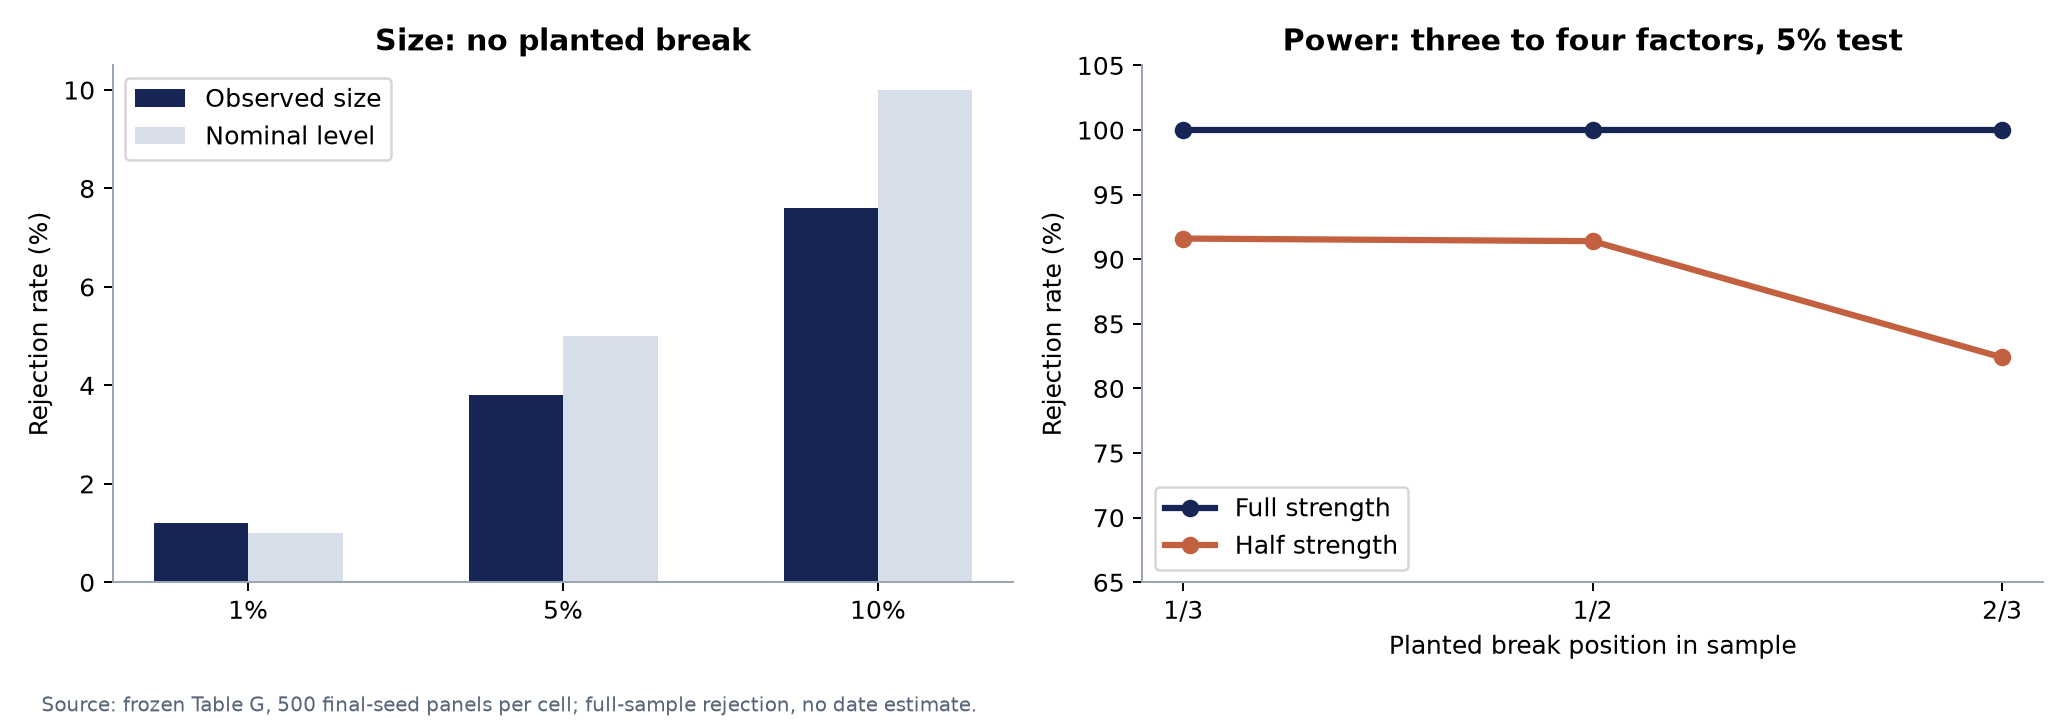

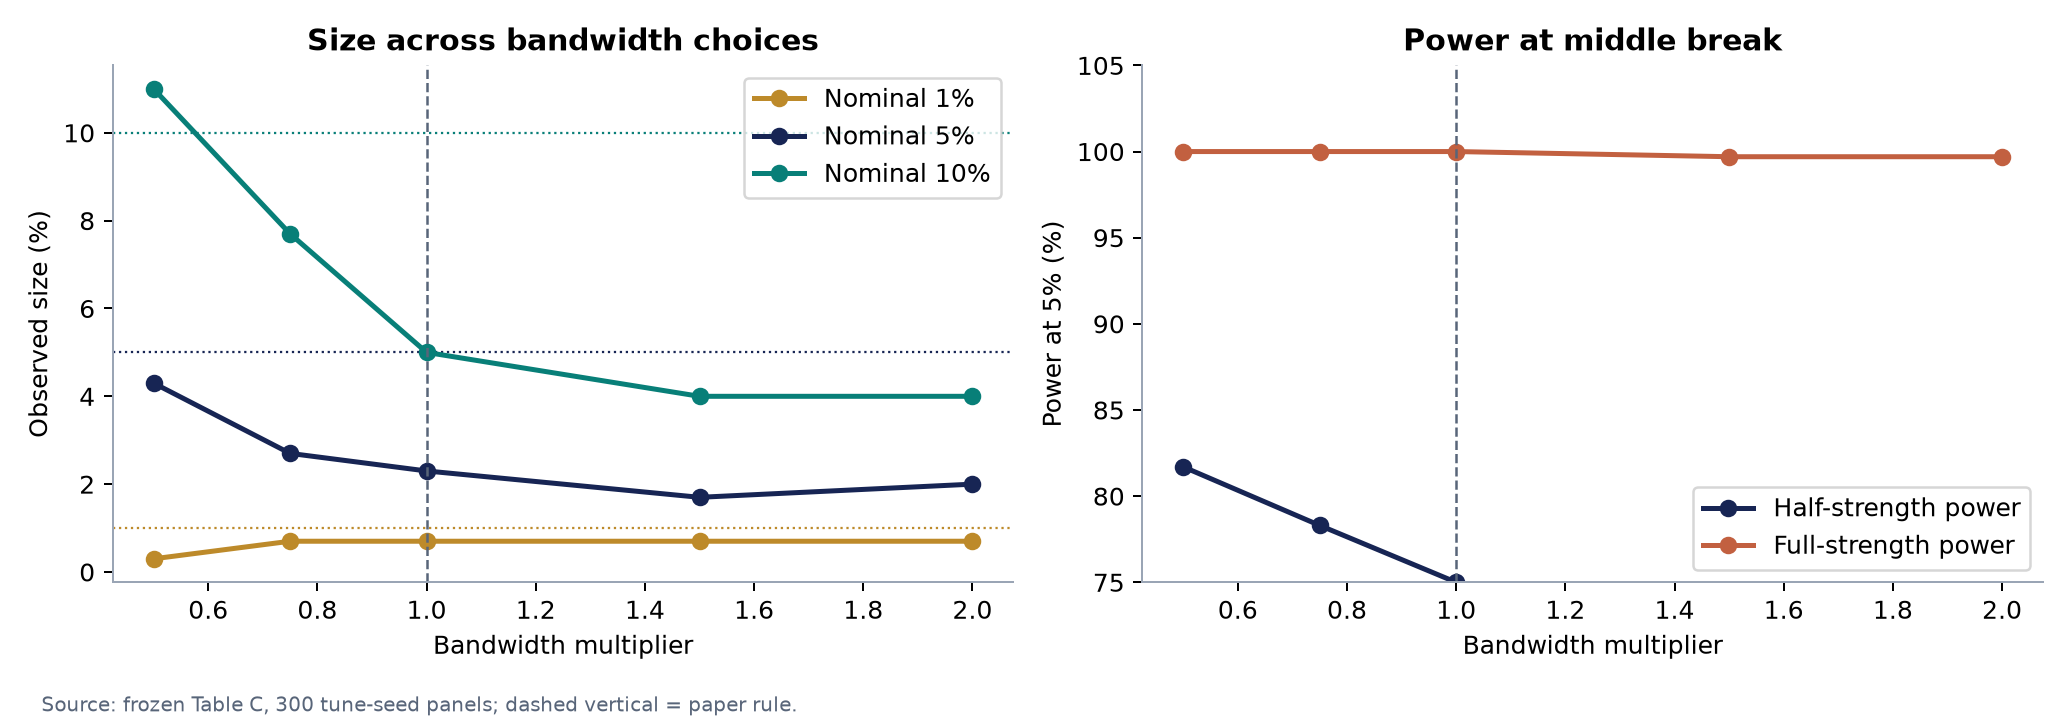

In [3]:
text = (ROOT / "results/final_tables.md").read_text(encoding="utf-8")
sec = text[text.index("## 表 G"):text.index("## 表 H")]
display(Markdown(sec))
fig("03_fullsample_size_power.png"); fig("04_bandwidth.png")

**结论**：5% 水平 size 3.8%，强第四因子 power 100%，半强度 82–92%。带宽越窄 power 越高、size 略升，论文规则（c = 1）合格。

## 3. 定日期是第二步：扫描偏晚，“先检验、再分割”更准

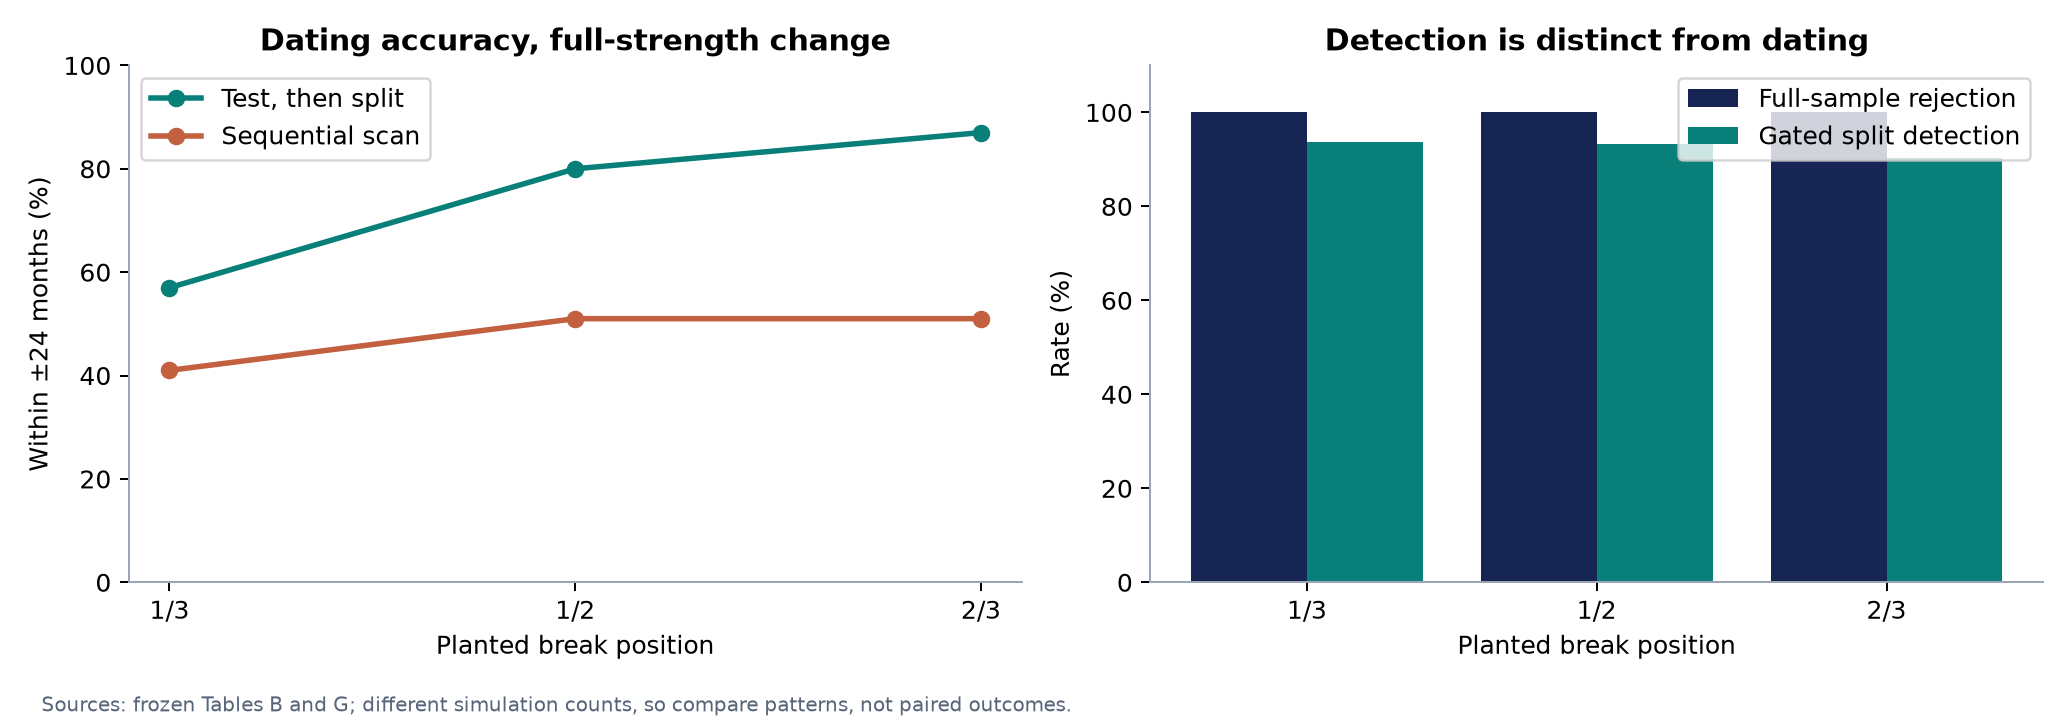

In [4]:
fig("06_dating.png")

**结论**：逐窗扫描在强断点下平均晚约 20 个月；先做全样本检验、拒绝后用最小二乘分割，中后段强断点 80–87% 落在 ±24 个月内。定日期以检验有效为前提，所以后面的工作集中在检验本身。

## 4. 核心问题：真实残差高度持续

固定载荷 PCA 残差的一阶自相关中位数（全样本、标准化）：

In [5]:
acf = csv("residual_acf_summary.csv")
acf = acf[acf.fit.isin(["global_PCA_standardized", "local_PCA_standardized"]) & acf["rank"].isin([3, 4])]
acf.pivot_table(index=["panel", "rank"], columns="fit", values="median_rho1").round(2)

fit                 global_PCA_standardized  local_PCA_standardized
panel         rank                                                 
CMT_full_8    3                        0.73                    0.62
              4                        0.55                    0.47
CMT_matched_8 3                        0.65                    0.49
              4                        0.42                    0.33
JKV_full_17   3                        0.63                    0.45
              4                        0.49                    0.33
JKV_matched_8 3                        0.64                    0.42
              4                        0.37                    0.27

所有期限的一阶自相关都为正，中位数约 0.6–0.7。原检验的 bootstrap 却按“各月独立”生成噪音。第 9 周的压力测试已经显示：只要噪音是 AR(0.3)，没有任何断点，原检验也几乎 100% 拒绝。

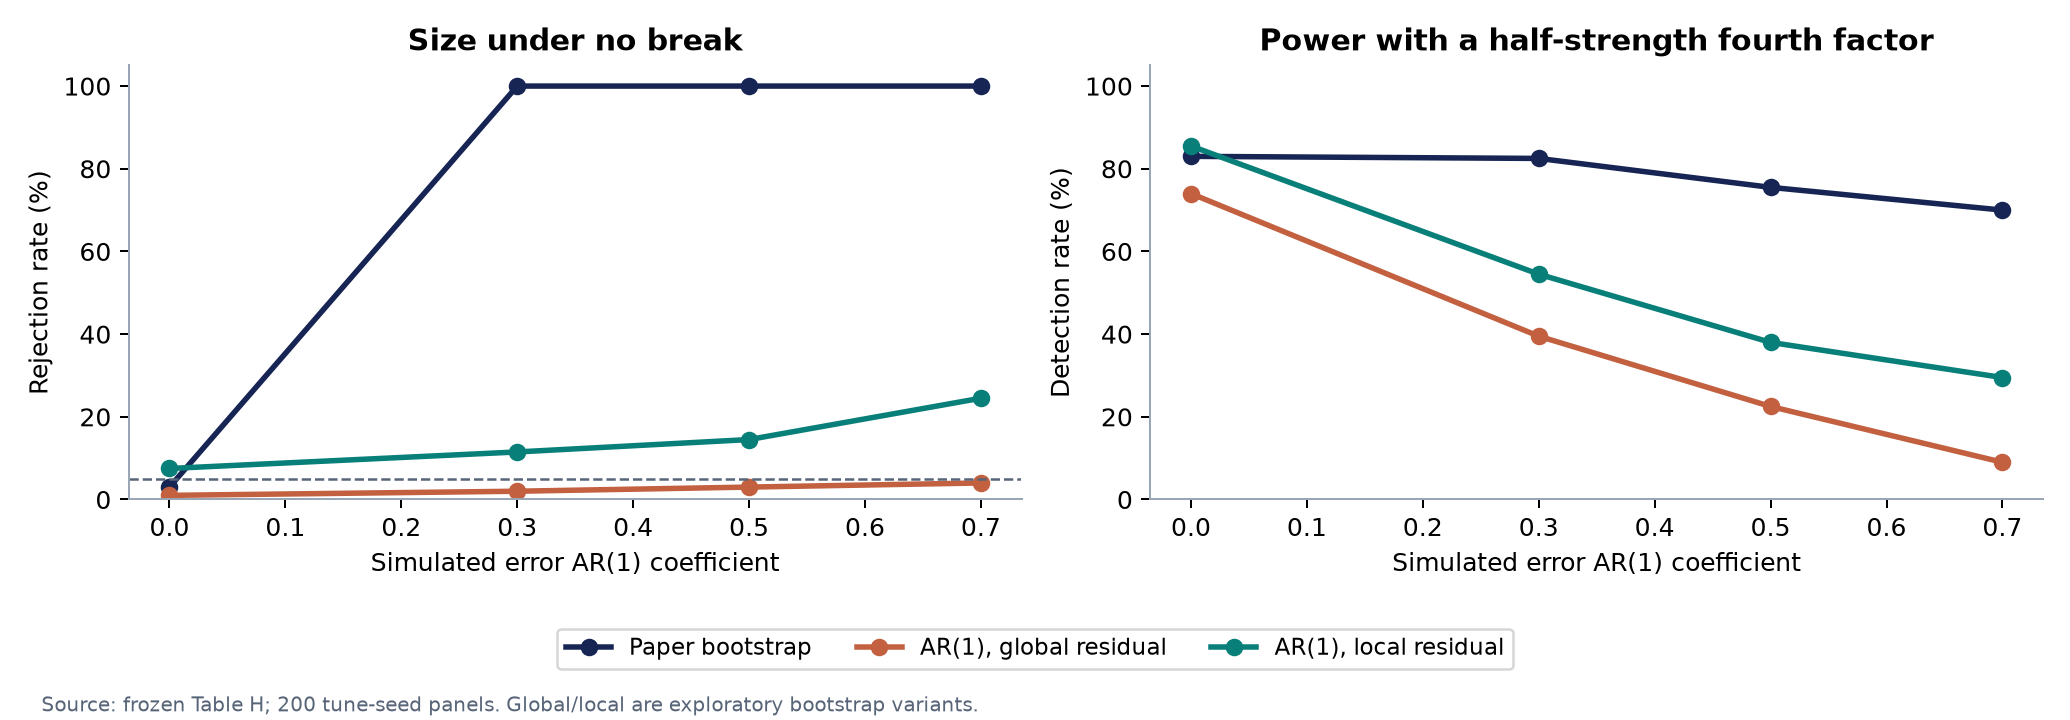

In [6]:
fig("05_serial_dependence.png")

## 5. 第 10 周：给 bootstrap 加 AR(1)

在 T = 240 的校准模拟里比较：原 bootstrap（paper_iid）、用全局残差估 AR(1) 的 bootstrap（ar1_global）、局部残差版（ar1_local）。每格 = size % / power %（power：载荷在样本中点按半强度变化）。

In [7]:
b = csv("ar_bootstrap_study_summary.csv")
pairs = [("Independent", "null_iid", "alt_loading_iid"), ("AR(0.3)", "null_ar03", "alt_loading_ar03"), ("AR(0.6)", "null_ar06", "alt_loading_ar06")]
rows = []
for m, lab in [("paper_iid", "Original"), ("ar1_global", "+ AR(1) bootstrap, global residual"), ("ar1_local", "+ AR(1) bootstrap, local residual")]:
    for ds in ("JKV17", "Treasury8"):
        g = lambda sc: 100 * b[(b.dataset == ds) & (b.scenario == sc) & (b.method == m)].rejection_rate.iloc[0]
        rows.append({"method": lab, "data": ds, **{n: f"{g(a):.1f} / {g(c):.1f}" for n, a, c in pairs}})
pd.DataFrame(rows).set_index(["method", "data"])

Independent      AR(0.3)        AR(0.6)
method                             data                                              
Original                           JKV17       3.5 / 44.0  95.0 / 99.5  100.0 / 100.0
                                   Treasury8   3.5 / 72.5  62.5 / 97.0  100.0 / 100.0
+ AR(1) bootstrap, global residual JKV17       3.5 / 39.0   3.0 / 18.0      1.0 / 7.5
                                   Treasury8   3.5 / 68.0   4.5 / 35.0     1.5 / 23.0
+ AR(1) bootstrap, local residual  JKV17      11.0 / 61.0  11.0 / 43.5    14.5 / 47.5
                                   Treasury8   6.0 / 80.0   9.0 / 55.0    16.0 / 47.0

**结论**：AR(1) bootstrap（全局残差）把 size 拉回 1–4.5%，但 AR(0.6) 下 power 只剩 7.5% / 23%；局部残差版 power 回升，但 size 11–16%。单靠换 bootstrap 不够。

## 6. 第 11 周：导师的建议——因子数固定时先调带宽

导师反馈：如果 Su–Wang 估计后的残差仍有强序列相关，要么带宽太大，要么因子太少；因子数固定（3 或 4）时，检验前要调好 h。

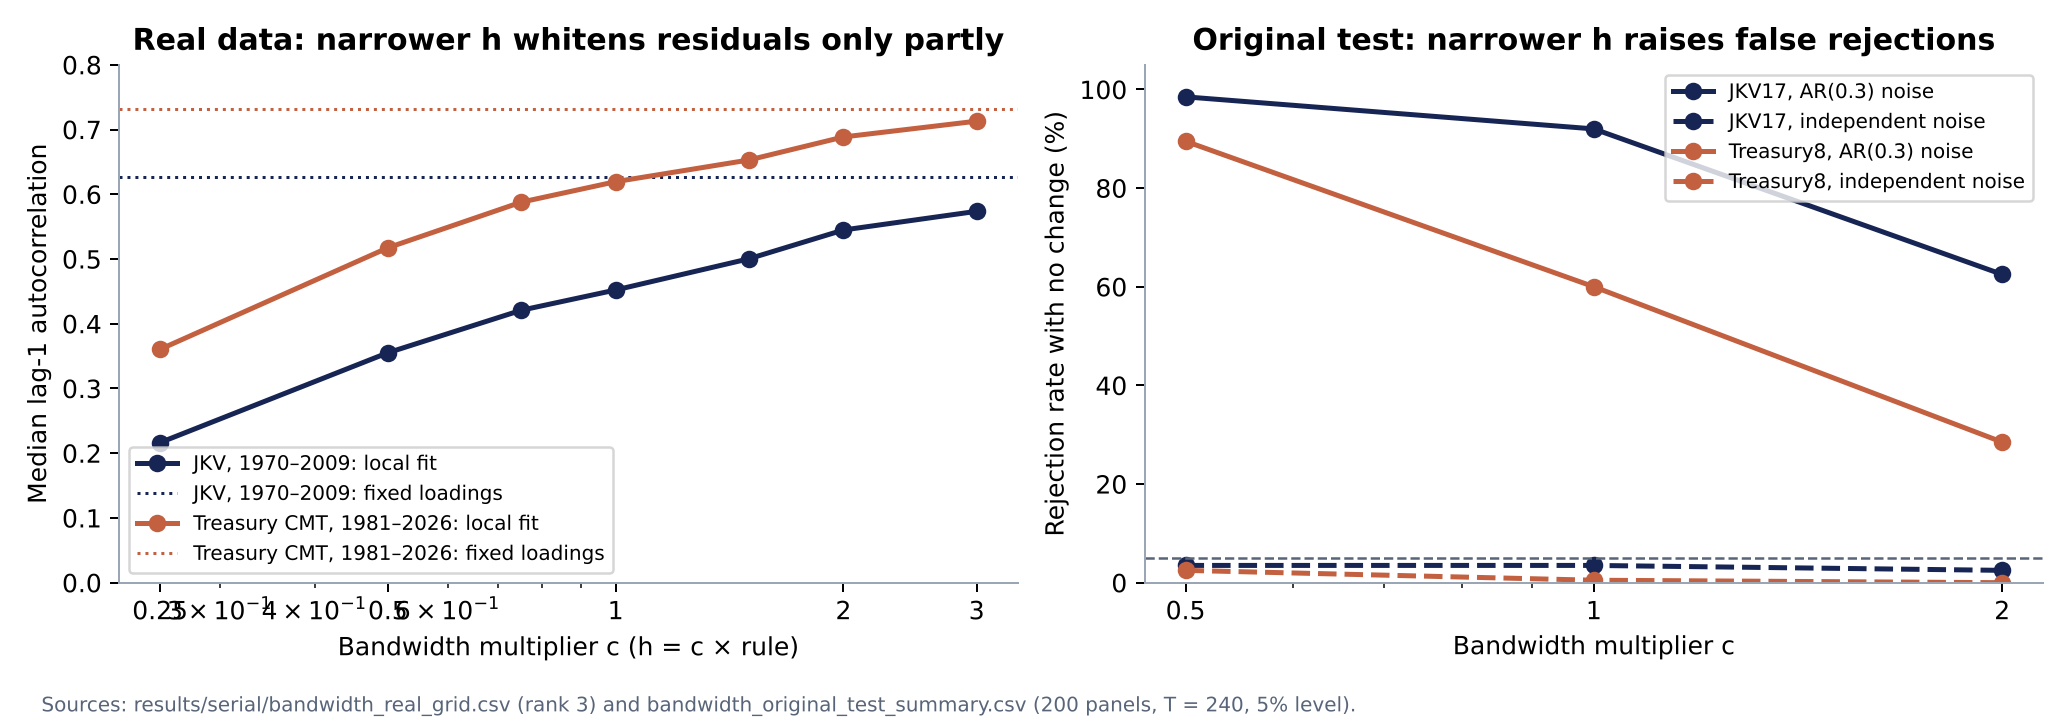

In [8]:
fig("07_bandwidth_persistence.png")

In [9]:
g = csv("bandwidth_real_grid.csv")
g = g[g["rank"] == 3].pivot_table(index="scale", columns="panel", values="median_rho1").round(2)
g.index = ["fixed loadings" if c == 0 else f"local, c = {c:g}" for c in g.index]
display(g)
display(csv("bandwidth_selected_cv_summary.csv").round(3))

panel,CMT_full_8,CMT_matched_8,GSW_modern_8,JKV_full_17,JKV_matched_8,Treasury_modern_8
fixed loadings,0.73,0.65,0.84,0.63,0.64,0.80
"local, c = 0.25",0.36,0.20,0.27,0.22,0.14,0.34
"local, c = 0.5",0.52,0.37,0.51,0.36,0.31,0.57
"local, c = 0.75",0.59,0.46,0.60,0.42,0.39,0.62
"local, c = 1",0.62,0.49,0.64,0.45,0.42,0.65
"local, c = 1.5",0.65,0.54,0.69,0.50,0.45,0.69
"local, c = 2",0.69,0.58,0.71,0.54,0.49,0.72
"local, c = 3",0.71,0.62,0.76,0.57,0.54,0.76


,dataset,scenario,rank,true_error_rho,alternative,reps,reject_rate,selected_c_median,median_estimated_ar,mean_draws,mc_se
0,JKV17,alt3to4_ar03,3,0.3,True,100,0.13,2.0,0.299,61.92,0.034
1,JKV17,null3_ar03,3,0.3,False,100,0.01,2.0,0.278,23.17,0.010
2,JKV17,null3_iid,3,0.0,False,100,0.03,2.0,-0.012,24.76,0.017
3,JKV17,null4_ar03,4,0.3,False,100,0.03,2.0,0.274,28.07,0.017
4,Treasury8,alt3to4_ar03,3,0.3,True,100,0.12,2.0,0.324,56.16,0.032
5,Treasury8,null3_ar03,3,0.3,False,100,0.03,2.0,0.280,25.30,0.017
6,Treasury8,null3_iid,3,0.0,False,100,0.01,2.0,-0.014,23.76,0.010
7,Treasury8,null4_ar03,4,0.3,False,100,0.04,2.0,0.276,32.17,0.020


**结论**：h 越窄，局部拟合残差的自相关越低（JKV 0.63 → 0.22），但从来消不掉；而在模拟里，窄带宽让原检验误报更多（AR(0.3) 下 JKV 从 62.5% 升到 98.5%），因为局部载荷把持续的噪音也“吸收”成了载荷变化。分块交叉验证选 h 再配 AR bootstrap，size 合格（1–4%），但 power 只有 12–13%。

## 7. 第 12 周：识别边界

$y_t=\Lambda_3 f_t+\lambda_4 g_t+e_t$ 也可以写成 $y_t=\Lambda_3 f_t+e_t^*$，$e_t^*=\lambda_4 g_t+e_t$。如果允许误差任意变化，“新增共同因子”和“误差共同成分变化”在观测上等价。一个条件性的 Nelson–Siegel 形状检验（预先指定前 120 个月稳定）在稳定误差下 size 合格，但只要后半段噪音波动放大 1.5 倍、载荷不变，就拒绝 93–99%。

In [10]:
k = csv("shape_test_key_results.csv")
k = k[k.method.isin(["shape_variance", "variance_volshift", "correlation_corrshift"])]
k.pivot_table(index=["method", "scenario"], columns="dataset", values="reject_percent")

dataset                                    JKV17  Treasury8
method                scenario                             
correlation_corrshift null_corrshift_ar03  100.0       50.0
                      null_corrshift_ar06  100.0       42.0
shape_variance        factor_ar03           90.4       72.6
                      factor_ar06           73.4       58.4
                      factor_hetero         83.4       61.4
                      null_ar03              4.0        5.4
                      null_ar06              4.8        5.6
                      null_hetero            4.2        6.2
                      null_iid               4.6        3.6
variance_volshift     null_vol_ar03         99.0       99.0
                      null_vol_ar06         99.0       93.0

## 8. 回到 Su–Wang 本身：实现核对，以及在原文 DGP 里加 AR 误差

1. 用 Octave 运行作者 MATLAB，在同一矩阵上与我们的实现对照：SM1、SM2 逐位一致（12 位有效数字）。
2. 发现：论文的 $\hat B$、$\hat V_1$ 依赖局部特征向量的符号约定（同一 JKV 矩阵上 $\hat J$ 在 60.9 与 71.3 之间），建议用 Procrustes 对齐。
3. 在 Su–Wang 自己的 DGP 1（N = T = 100）里加入 AR 误差：原检验 size 从 2% 升到 88%（AR 0.3）和 100%（AR 0.6）。**过度拒绝是方法在序列相关下的失效，不是数据或代码问题。**

,case,R,oct_SM1,port_SM1,oct_SM2,port_SM2,"port_J_paper(B3,V4)",wk10_J_noboundary
0,JKV17_full480,3,34.7817,34.7817,17.2040,17.2040,82.1126,78.9290
1,JKV17_full480,4,22.1044,22.1044,14.7491,14.7491,57.5475,57.1308
2,JKV17_first240,3,28.5006,28.5006,15.4999,15.4999,60.9257,71.2661
3,JKV17_first240,4,15.0576,15.0576,11.2081,11.2081,28.9636,34.2748
4,SuWang_DGP1_N100_T100,2,3.4609,3.4609,3.0421,3.0421,-1.4843,2.1169
5,SuWang_DGP1_N100_T100,3,36.8868,36.8868,33.9632,33.9632,9.7194,12.2083


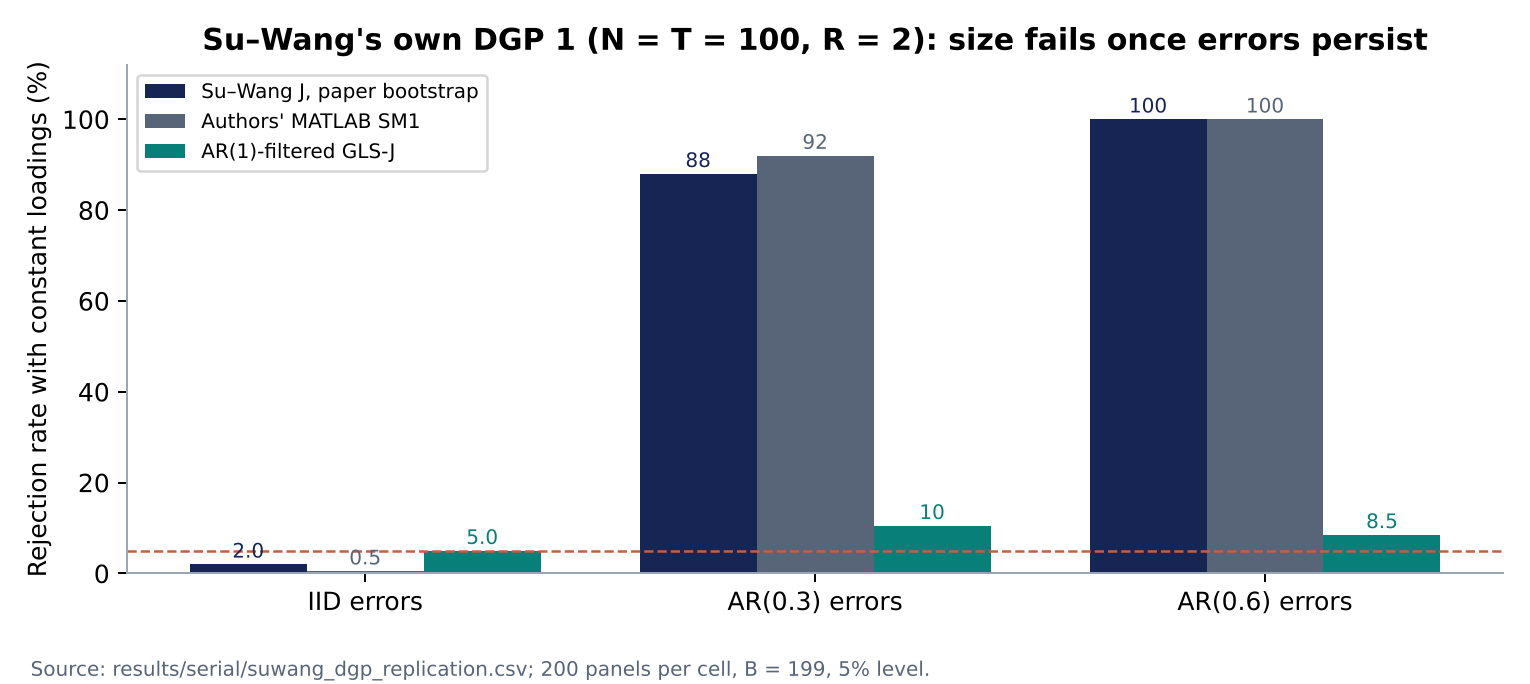

In [11]:
display(csv("matlab_equivalence.csv")[["case", "R", "oct_SM1", "port_SM1", "oct_SM2", "port_SM2", "port_J_paper(B3,V4)", "wk10_J_noboundary"]].round(4))
fig("08_suwang_dgp_serial.png", 760)

## 9. 新方法：sieve-AR GLS-J

思路：Su–Wang 的比较在噪音不可预测时有效，所以先把每个期限噪音里可预测的部分滤掉，再比较局部和全样本载荷，最后用把持续性放回去的 bootstrap 判断显著性。

1. **滤波**：PCA 估计因子；合并各期限用 AIC 选一个 AR 阶数 $\hat p\le 6$；每个期限拟合 AR($\hat p$)，对收益率和因子做准差分（Breitung–Tenhofen 2011 的 GLS）。
2. **比较**：在滤波后的数据上，核加权局部载荷 $\hat\lambda_i(t)$ 对比全样本载荷 $\hat\lambda_i$：
   $\hat M_{GLS}=\frac1{NT}\sum_{i,t}\big[(\hat\lambda_i(t)-\hat\lambda_i)'\tilde z_{it}\big]^2/\hat\sigma^2_{u,i}$，带宽 $h=2h_0$，事先固定。
3. **校准**：每个月一个随机符号（所有期限共用，保留跨期限相关）乘到 AR 创新上，用拟合的 AR 递推重建噪音，每次都重新估计（sieve bootstrap；Kreiss 1992，Bühlmann 1997）。

保留 Su–Wang 的：原假设、局部 vs 全样本的比较、核、3/4 因子框架。新的：先白化噪音、AR 阶数由数据决定、bootstrap 带动态。

下面现场跑一个例子（JKV 校准，AR(0.6) 噪音，T = 240，B = 99）：一个载荷不变的面板，一个载荷在中点变化的面板。

In [12]:
model = sr.load_serial_model("JKV17")
for sc in ("null_ar06", "alt_load_ar06_s1"):
    y, rank = sr.serial_panel(model, sc, 240, sr.scenario_seed(sc, 0))
    out = sr.gls_j_test(sr.standardise(y), rank, boot=99, seed=1, early=False)
    print(f"{sc:18s} AR order={out['p_ar']}  M_GLS={out['stat']:.4f}  bootstrap p={out['p']:.3f}  reject at 5%: {out['reject']}")

null_ar06          AR order=1  M_GLS=0.0107  bootstrap p=0.990  reject at 5%: False


alt_load_ar06_s1   AR order=1  M_GLS=0.0238  bootstrap p=0.010  reject at 5%: True


## 10. 新方法的 size 和 power

每格 250 个面板，T = 240，B = 199，5% 水平；250 次时 5% 附近的 Monte Carlo 95% 区间约为 2.3–7.7%。

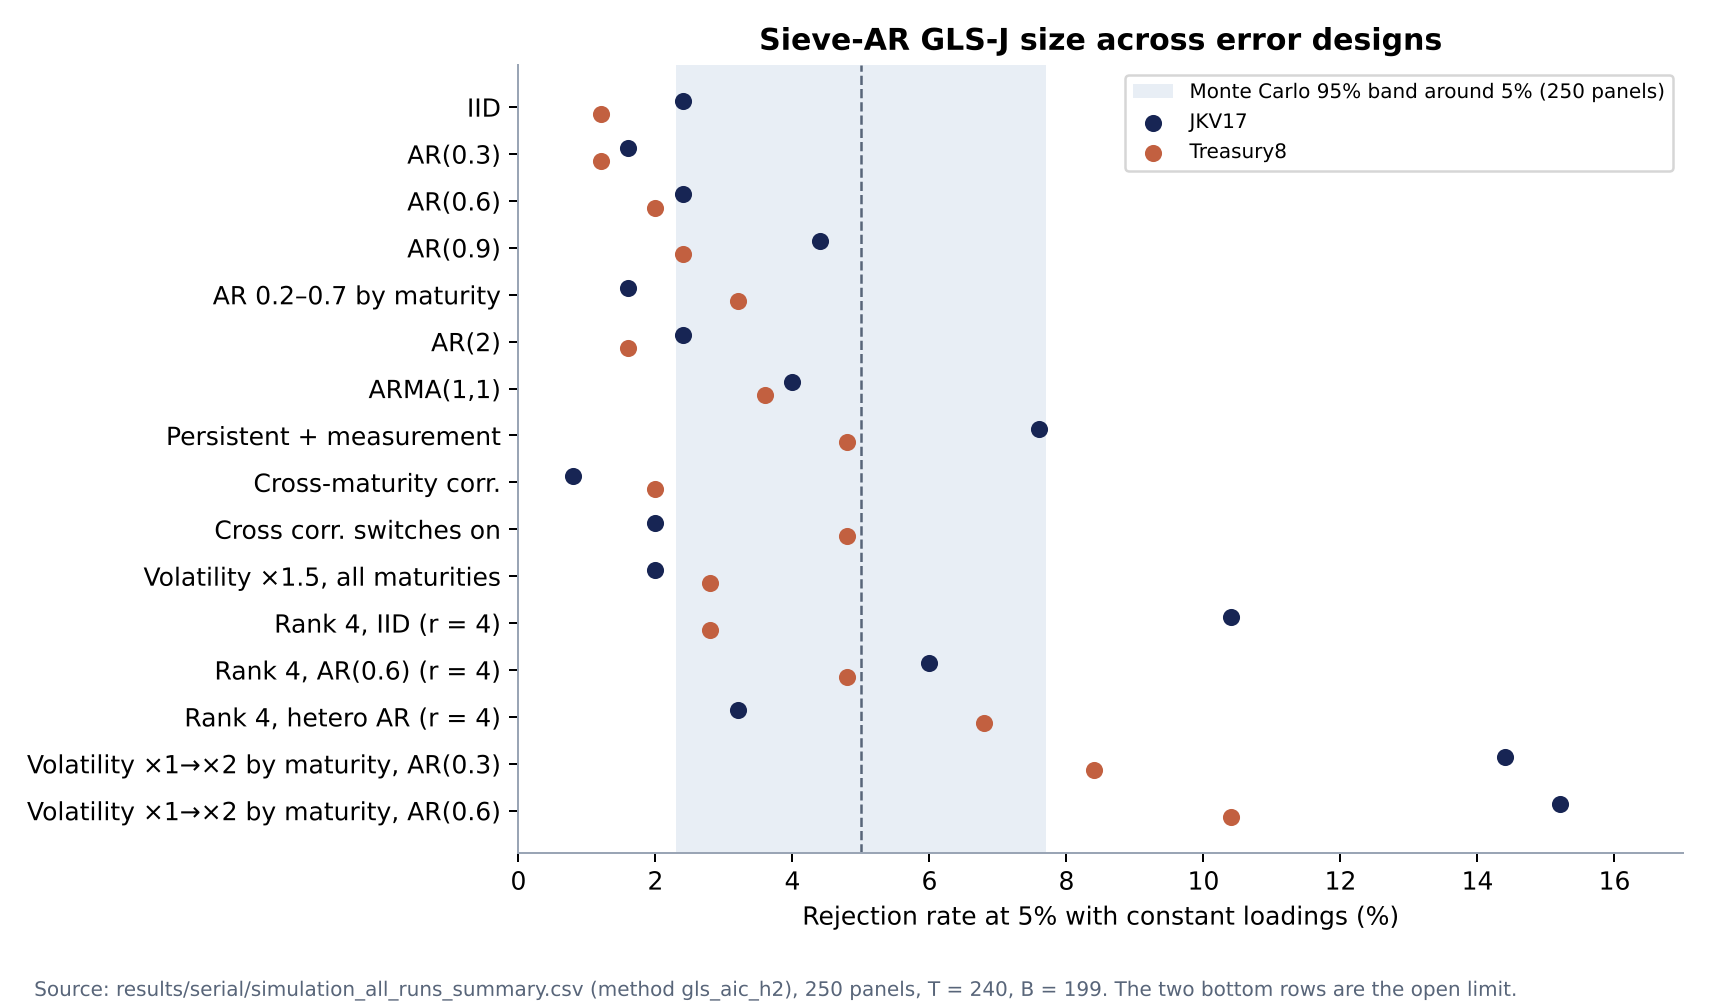

,JKV17,Treasury8
scenario,,
alt_fac_ar03,23.6,9.2
alt_fac_ar06_s1,74.0,72.0
alt_load_ar06,20.8,44.4
alt_load_ar06_s025,5.6,7.6
alt_load_ar06_s075,47.2,76.0
alt_load_ar06_s1,62.8,94.8
alt_load_arma11_s1,63.2,90.8
alt_load_crosschg_s1,63.6,93.6
alt_load_hetero_s075,50.0,76.8


In [13]:
fig("09_sieve_gls_size.png", 760)
fm = csv("final_method_size_power.csv").set_index("scenario")
fm

和第 10 周的方法同口径对比（每格 size % / power %，power = 半强度载荷变化）：

Independent      AR(0.3)        AR(0.6)
method               data                                             
Original test        JKV17      3.5 / 44.0  95.0 / 99.5  100.0 / 100.0
                     Treasury8  3.5 / 72.5  62.5 / 97.0  100.0 / 100.0
+ AR(1) bootstrap    JKV17      3.5 / 39.0   3.0 / 18.0      1.0 / 7.5
                     Treasury8  3.5 / 68.0   4.5 / 35.0     1.5 / 23.0
Sieve-AR GLS-J (new) JKV17      2.4 / 49.6   1.6 / 26.4     2.4 / 20.8
                     Treasury8  1.2 / 76.8   1.2 / 55.2     2.0 / 44.4

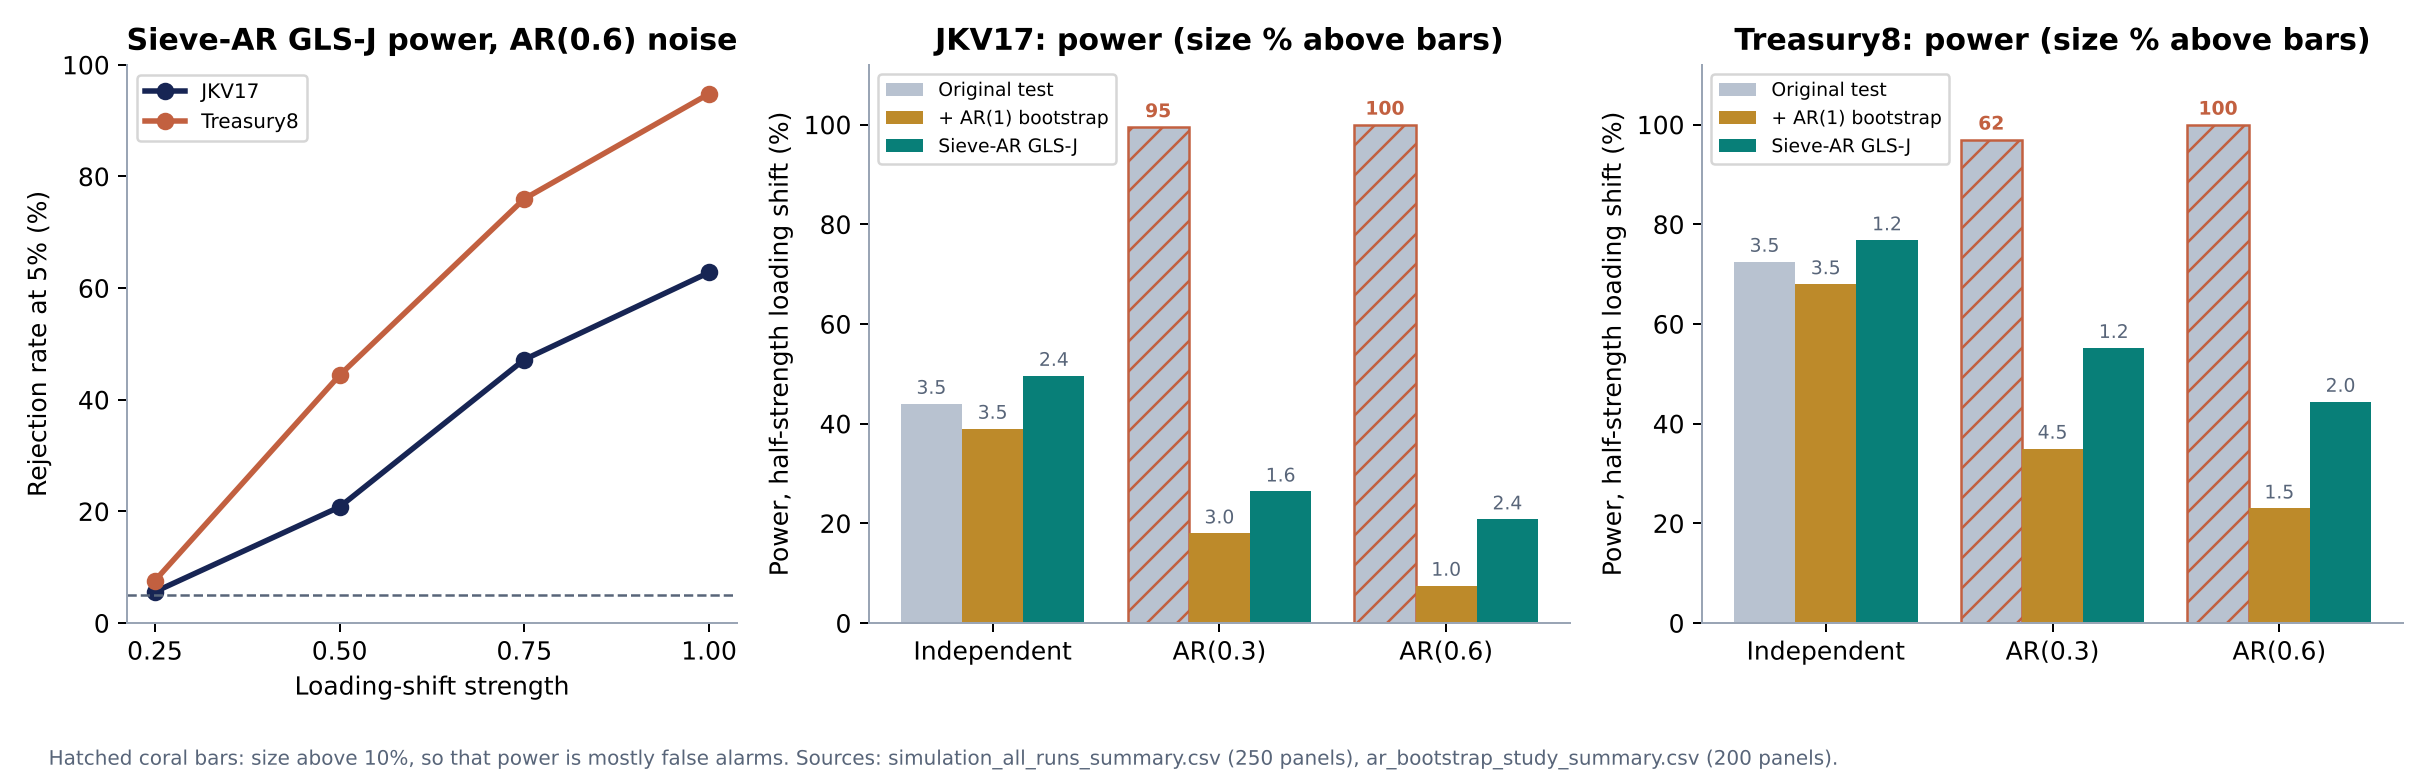

In [14]:
cell = {(r.dataset, r.scenario): r.reject_pct for r in csv("simulation_all_runs_summary.csv").query("method == 'gls_aic_h2'").drop_duplicates(["dataset", "scenario"], keep="last").itertuples()}
rows = []
for m, lab in [("paper_iid", "Original test"), ("ar1_global", "+ AR(1) bootstrap")]:
    for ds in ("JKV17", "Treasury8"):
        g = lambda sc: 100 * b[(b.dataset == ds) & (b.scenario == sc) & (b.method == m)].rejection_rate.iloc[0]
        rows.append({"method": lab, "data": ds, **{n: f"{g(a):.1f} / {g(c):.1f}" for n, a, c in pairs}})
new_pairs = [("Independent", "null_iid", "alt_load_iid"), ("AR(0.3)", "null_ar03", "alt_load_ar03"), ("AR(0.6)", "null_ar06", "alt_load_ar06")]
for ds in ("JKV17", "Treasury8"):
    rows.append({"method": "Sieve-AR GLS-J (new)", "data": ds, **{n: f"{cell[(ds, a)]:.1f} / {cell[(ds, c)]:.1f}" for n, a, c in new_pairs}})
display(pd.DataFrame(rows).set_index(["method", "data"]))
fig("10_sieve_gls_power.png", 1000)

**为什么是这些设定（消融）**：同一批种子下，各变体在关键 null 和备择上的拒绝率（%）。

In [15]:
a = csv("simulation_all_runs_summary.csv").drop_duplicates(["dataset", "scenario", "method"], keep="last")
lab = {"dwb_J_l12": "Original J + dependent wild bootstrap (l=12)", "gls_M_wild": "GLS-J, AR(1), h0",
       "gls_h05": "GLS-J, AR(1), 0.5 h0", "gls_h2": "GLS-J, AR(1), 2 h0", "gls_sieve_h2": "GLS-J, sieve BIC, 2 h0",
       "gls_aic_h2": "GLS-J, sieve AIC, 2 h0 (final)", "gls_bc": "GLS-J + Kendall bias correction",
       "gls_iter": "GLS-J + iterated factors", "swqd_J_r": "Quasi-differenced original J",
       "gls_split_h2": "Two-half weighted PCA", "gls_aicT_h2": "AIC, T-growing pmax = 14"}
sc = ["null_ar06", "null_arma11", "null_meas", "alt_load_ar06", "alt_load_ar06_s1"]
t = a[a.method.isin(lab) & a.scenario.isin(sc)].pivot_table(index="method", columns=["scenario", "dataset"], values="reject_pct")
t.index = [lab[i] for i in t.index]
t.round(1)

scenario                                     alt_load_ar06           alt_load_ar06_s1           null_ar06           null_arma11           null_meas          
dataset                                              JKV17 Treasury8            JKV17 Treasury8     JKV17 Treasury8       JKV17 Treasury8     JKV17 Treasury8
Original J + dependent wild bootstrap (l=12)          52.0      51.5             64.0      87.5      23.5      19.0         NaN       NaN       NaN       NaN
GLS-J, AR(1), h0                                      19.2      34.0             58.0      92.8       2.4       1.6        73.6      47.6     100.0      98.0
AIC, T-growing pmax = 14                              18.0      44.0             58.0      96.0       2.0       1.0         NaN       NaN      12.0       5.0
GLS-J, sieve AIC, 2 h0 (final)                        20.8      44.4             62.8      94.8       2.4       2.0         4.0       3.6       7.6       4.8
GLS-J + Kendall bias correction                       19.6      33.2             58.8      92.4       2.8       2.0         NaN       NaN       NaN       NaN
GLS-J, AR(1), 0.5 h0                                  17.6      30.4             50.8      82.4       2.8       4.0        93.2      61.2     100.0      99.6
GLS-J, AR(1), 2 h0                                    20.8      44.4             62.8      94.8       2.4       1.2        40.0      23.2      99.2      83.2
GLS-J + iterated factors                              16.4      38.4             51.2      93.2       1.2       2.4         NaN       NaN       NaN       NaN
GLS-J, sieve BIC, 2 h0                                20.8      44.4             62.8      94.8       2.4       1.2         6.4       8.8      34.4      18.0
Two-half weighted PCA                                 16.0       3.0             25.0       3.0      21.0       1.0         NaN       NaN      29.0       3.0
Quasi-differenced original J                           0.8       0.0              0.8       7.2       0.4       0.0         NaN       NaN       NaN       NaN

读法：
- **AIC 而不是 BIC、而不是固定 AR(1)**：AR(1) 在 ARMA(1,1) 和“持续成分 + 测量误差”下 size 74% / 100%；BIC 选的阶数偏短（13% / 56%）；AIC 降到 4.0% / 7.6%。
- **h = 2h₀**：size 不变，Treasury 半强度 power 从 34% 升到 44%。
- **负面结果**：原 J 套 dependent wild bootstrap 在 AR(0.6) 下 size 19–24%；准差分后原样用 Su–Wang $\hat J$ 几乎没有 power；Kendall 修正、迭代因子、局部方差、两段加权 PCA 都没有改进。

**仍然存在的弱点**：各期限噪音波动按不同比例变化（短端 ×1、长端 ×2）时 size 为 14–15%（JKV）和 8–10%（Treasury）。这是第 7 节识别边界的一个具体形态，论文中作为假设写明。

## 11. 代码对照：仓库版本与原探索代码逐面板一致

`code/serial_robust.py` 是探索代码的整理版。40 个面板（两套校准 × 10 个情景 × 2 次）上，DGP 输出差异 ≤ 1.4e-13（JKV 校准文件的舍入），统计量差异 ≤ 3e-16，p 值、5% 决策、bootstrap 次数和 AR 阶数完全相同。

In [16]:
eq = csv("port_equivalence.csv")
print("panels:", len(eq), "| all p/decision/draws/order equal:", bool(eq[["same_p", "same_decision", "same_draws", "same_ar_order"]].all().all()))
y, rank = sr.serial_panel(sr.load_serial_model("Treasury8"), "null_ar06", 240, sr.scenario_seed("null_ar06", 0))
print("spot check, Treasury8 null_ar06 rep 0:", sr.gls_j_test(sr.standardise(y), rank, boot=49, seed=sr.scenario_seed("null_ar06", 0) + 13))
eq.head()

panels: 40 | all p/decision/draws/order equal: True


spot check, Treasury8 null_ar06 rep 0: {'stat': 0.017895620054070034, 'p': 0.06, 'reject': False, 'draws': 47, 'p_ar': 3, 'h': 0.36918884212514824}


,dataset,scenario,rep,max_abs_panel_diff,stat_diff,same_p,same_decision,same_draws,same_ar_order
0,JKV17,null_iid,0,6.300000e-14,-1.200000e-16,True,True,True,True
1,JKV17,null_iid,1,3.300000e-14,-1.500000e-16,True,True,True,True
2,JKV17,null_ar06,0,4.800000e-14,6.400000e-17,True,True,True,True
3,JKV17,null_ar06,1,9.400000e-14,-9.900000e-17,True,True,True,True
4,JKV17,null_meas,0,1.300000e-13,2.800000e-16,True,True,True,True


## 12. 初步实证（探索性，未事先锁定设定）

B = 999，AIC 阶数上限 6（括号外）和 12（稳健性）。JKV 是冻结结果；Treasury 用仓库里的 H.15 文件重跑，样本到 2026 年 8 月（探索性原始运行包含 2026 年 9 月的不完整月份，所以 1990–2026 与 2010–2026 的 p 值略有不同）。

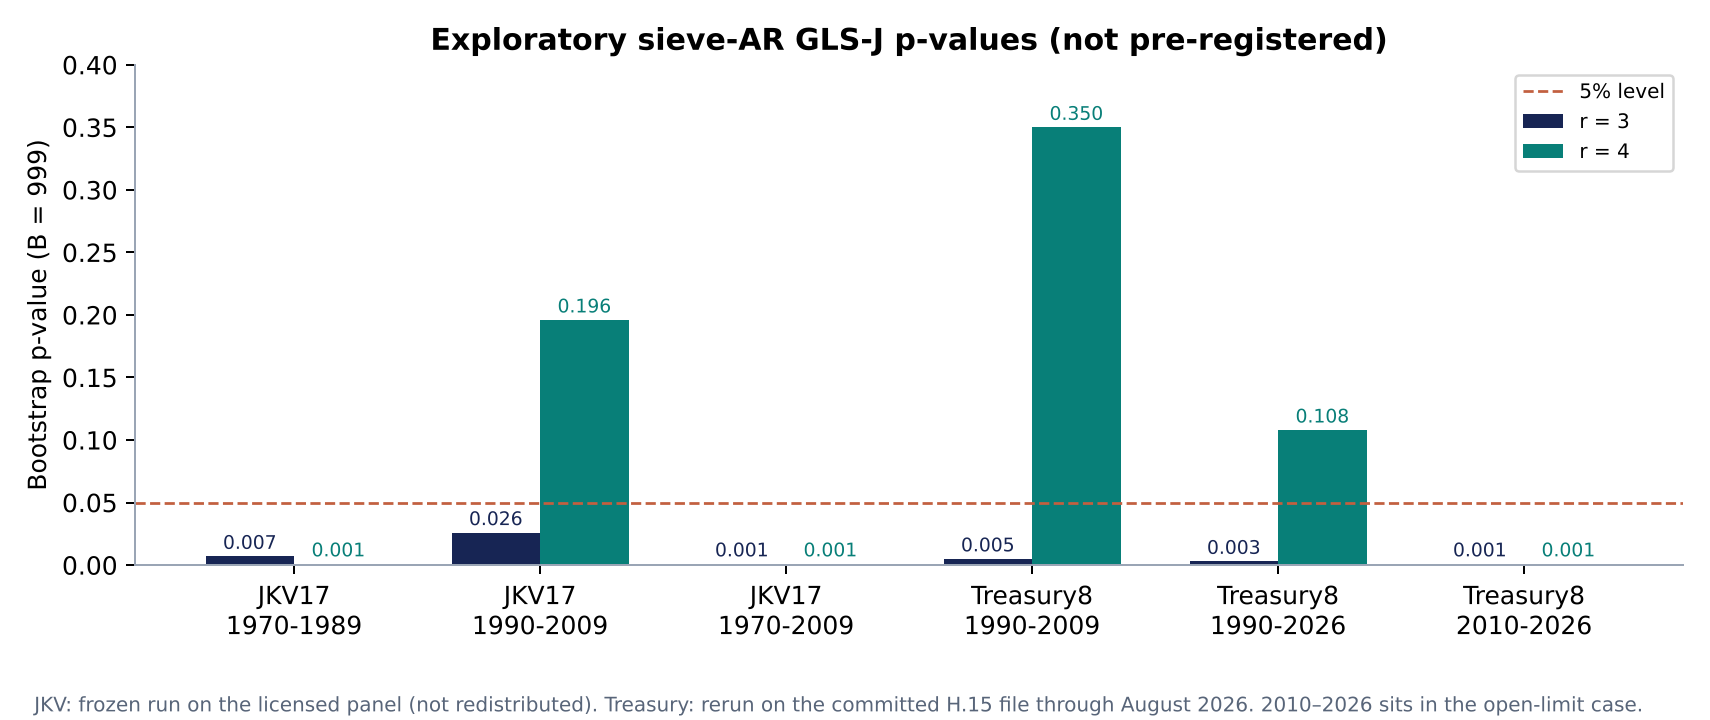

p (pmax 6)  AR order  p (pmax 12)  AR order 12
sample              r                                                
JKV17 1970-1989     3       0.007         3        0.050           12
                    4       0.001         3        0.049           12
JKV17 1990-2009     3       0.026         6        0.022            7
                    4       0.196         6        0.195            7
JKV17 1970-2009     3       0.001         6        0.001           12
                    4       0.001         6        0.001           12
Treasury8 1990-2009 3       0.005         6        0.005            6
                    4       0.350         6        0.350            6
Treasury8 1990-2026 3       0.003         6        0.002            7
                    4       0.108         6        0.108            6
Treasury8 2010-2026 3       0.001         1        0.001            2
                    4       0.001         1        0.001           12

In [17]:
fig("11_empirical_pvalues.png", 820)
j6, j12 = csv("empirical_frozen_pmax6.csv"), csv("empirical_frozen_pmax12.csv")
tp = csv("empirical_treasury8_public.csv")
rows = []
for s in ["JKV17 1970-1989", "JKV17 1990-2009", "JKV17 1970-2009"]:
    for r in (3, 4):
        a6 = j6[(j6["sample"] == s) & (j6["rank"] == r)].iloc[0]; a12 = j12[(j12["sample"] == s) & (j12["rank"] == r)].iloc[0]
        rows.append({"sample": s, "r": r, "p (pmax 6)": a6.p_value, "AR order": a6.ar_order, "p (pmax 12)": a12.p_value, "AR order 12": a12.ar_order})
for s in ["Treasury8 1990-2009", "Treasury8 1990-2026", "Treasury8 2010-2026"]:
    for r in (3, 4):
        a6 = tp[(tp["sample"] == s) & (tp["rank"] == r) & (tp.pmax == 6)].iloc[0]; a12 = tp[(tp["sample"] == s) & (tp["rank"] == r) & (tp.pmax == 12)].iloc[0]
        rows.append({"sample": s, "r": r, "p (pmax 6)": a6.p_value, "AR order": a6.ar_order, "p (pmax 12)": a12.p_value, "AR order 12": a12.ar_order})
pd.DataFrame(rows).set_index(["sample", "r"])

现场重跑 Treasury 1990–2009（B = 199，较快；种子相同但抽样次数少，p 值和上表 B = 999 的数字有 Monte Carlo 差异，正式数字以上表为准）：

In [18]:
d = sr.treasury8_samples()["Treasury8 1990-2009"][sr.CMT8].to_numpy(float)
for r in (3, 4):
    o = sr.empirical_test(d, r, boot=199)
    print(f"Treasury8 1990-2009, r={r}: AR order={o['p_ar']}, p={o['p']:.3f}")

Treasury8 1990-2009, r=3: AR order=6, p=0.020


Treasury8 1990-2009, r=4: AR order=6, p=0.395


**解读**：
- 1990–2009 年，三因子固定载荷在两个面板上都被拒绝（p = 0.026 / 0.005），四因子不被拒绝（0.196 / 0.350）。三因子下看到的“载荷变化”可能部分是漏掉的第四个因子（与 Duffee 2011 的隐藏因子一致）。
- 1970–1989 对 AR 阶数敏感（pmax = 12 时 p ≈ 0.05），而且 pmax = 6 时阶数常顶到上限：论文必须报告阶数敏感性。
- 2010–2026 两种秩都拒绝，但这段含零利率下限，短端几乎不动，正好是“各期限波动不同比例变化”的弱点，暂不解读。
- 1990–2009 三因子残差后/前半段标准差之比为 1.03–1.92（JKV）和 1.05–1.48（Treasury），量级接近造成 8–16% size 的模拟设定，所以 r = 3 的拒绝不能全部归因于载荷变化。

## 13. 结论、局限和请老师决定的问题

**结论**
1. 独立误差下，原 Su–Wang 检验在收益率维度上 size 合格、power 高（第 9 周）。
2. 收益率残差持续性强；在 AR 误差下原检验几乎总是误报，在 Su–Wang 自己的 DGP 里也一样（88–100%）。调小带宽、AR(1) bootstrap 只能部分缓解，且以 power 为代价。
3. sieve-AR GLS-J 在 Su–Wang 框架内修正了这一点：32 个 null 格子中 27 格 size 0.8–7.6%，包括 AR(0.9)、AR(2)、ARMA(1,1)、测量误差、跨期限相关变化、同比例波动变化；power 高于 AR bootstrap。
4. 初步实证：1990–2009 三因子拒绝、四因子不拒绝。

**局限**：没有渐近理论；各期限波动不同比例变化时 size 8–15%；弱载荷变化（0.25 强度）基本检测不到；JKV r = 4、iid 误差 size 10.4%；实证未事先锁定。

**请老师决定**：在每个检验窗口内，能否假设各期限噪音波动大体稳定？还是按已知 regime（如 2008 年）切开窗口再检验？

**下一步**：(1) 锁定设定（样本、先 r = 3 再 r = 4、AIC 阶数规则、h = 2h₀、B = 999）后正式跑实证；(2) 用统计量的时间分解 $\frac1N\sum_i[\cdot]^2$ 随 t 的轮廓定位断点；(3) N 固定、T → ∞ 下的 bootstrap 一致性证明草稿。